In [1]:
from cmdstanpy import CmdStanModel
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
import seaborn as sns

az.style.use("arviz-doc")  # type: ignore

/Users/aleksijkraljic/Desktop/repos/phd/bayes_25/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/aleksijkraljic/Desktop/repos/phd/bayes_25/.venv/lib/python3.12/site-packages/arviz/__init__.py:39: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


# Bayesian Multiple Regression

In [2]:
class BayesianLinearRegression:
    def __init__(
        self,
        stan_file: str = "models/linear_regression.stan",
        fit_intercept: bool = True,
        center_data: bool = True,
    ):
        self.stan_file = stan_file
        self.model = CmdStanModel(stan_file=stan_file)
        self.fit_intercept = fit_intercept
        self.center_data = center_data

    def fit(self, X: pd.DataFrame, y: pd.Series, parallel_chains: int = 4):
        X_np = X.astype(float).to_numpy()

        if self.center_data:
            X_mean = X_np.mean(axis=0)
            X_np = X_np - X_mean

            y_mean = y.mean()
            y = y - y_mean

        if self.fit_intercept:
            X_np = np.hstack((np.ones((X_np.shape[0], 1)), X_np))

        data = {
            "N": X_np.shape[0],
            "y": y.astype(float),
            "X": X_np,
            "K": X_np.shape[1],
        }

        self.fit = self.model.sample(data=data, parallel_chains=parallel_chains)

        renamed_results = self._rename_results(self.fit.draws_pd(), X.columns.to_list())

        if self.center_data and self.fit_intercept:
            renamed_results["intercept"] = (
                renamed_results["intercept"]
                + y_mean
                - np.dot(X_mean, renamed_results[X.columns.to_list()].T)
            )
        return renamed_results, self.fit

    def diagnose(self, var_names: list = ["beta", "sigma"], visualize=True):
        print(self.fit.diagnose())
        if visualize:
            az.plot_trace(az.from_cmdstanpy(self.fit), var_names=var_names, compact=False)

    def summarize_fit(self):
        print(self.fit.summary())

    def visualize_posterior_distributions(
        self, var_names: list = ["beta", "sigma"], grid: tuple | None = None
    ):
        az.plot_posterior(
            az.from_cmdstanpy(self.fit), var_names=var_names, hdi_prob=0.95, grid=grid
        )
        plt.show()

    def _rename_results(self, df: pd.DataFrame, X_columns: list) -> pd.DataFrame:
        beta_columns = df.filter(like="beta").columns.to_list()
        if self.fit_intercept:
            mapping = {"beta[1]": "intercept"}
            beta_columns.remove("beta[1]")
            for i in range(0, len(beta_columns)):
                mapping[beta_columns[i]] = X_columns[i]
        else:
            mapping = {beta_columns[i]: f"beta_{X_columns[i]}" for i in range(len(beta_columns))}

        return df.rename(columns=mapping)

    def __repr__(self) -> str:
        return f"Bayesian Linear Regression Stan Model: {self.stan_file}"


# Data-Generating Process

In [3]:
# Simulate data: temperature → ice cream sales & shark attacks
np.random.seed(42)

n = 2000  # number of days/observations

# Outside air temperature (e.g., °C)
temperature = np.random.normal(loc=25, scale=5, size=n)

# Ice cream sales as a function of temperature
# (e.g., hundreds of units sold)
alpha_0, alpha_1 = 5.0, 0.3
icecream_sales = alpha_0 + alpha_1 * temperature + np.random.normal(0, 1.5, size=n)

# Shark attacks as a function of temperature
# (higher temperatures bring more swimmers → more attacks)
beta_0, beta_1 = -3.0, 0.2
shark_attacks = beta_0 + beta_1 * temperature + np.random.normal(0, 1.0, size=n)

# collider: common effect of ice cream sales and shark attacks
gamma0, gamma1, gamma2 = 0.0, 1.0, 3.0
emergency_response_activity = (
    gamma0 + gamma1 * icecream_sales + gamma2 * shark_attacks + np.random.normal(0, 2.0, size=n)
)

# Assemble into a DataFrame
shark_data = pd.DataFrame(
    {
        "temperature": temperature,
        "icecream_sales": icecream_sales,
        "shark_attacks": shark_attacks,
        "emergency_response_activity": emergency_response_activity,
    }
)

shark_data.head()

,temperature,icecream_sales,shark_attacks,emergency_response_activity
0,27.483571,12.232304,1.633221,14.903803
1,24.308678,12.075826,1.830532,16.305561
2,28.238443,12.282903,2.665705,18.395899
3,32.615149,14.322602,3.995660,25.213591
4,23.829233,9.308348,0.398988,10.077012


# Histograms for each variable and correlation heatmap

/var/folders/w2/9c3nwdfn5j9g0_gpy7gsbspc0000gn/T/ipykernel_28840/1345163549.py:23: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


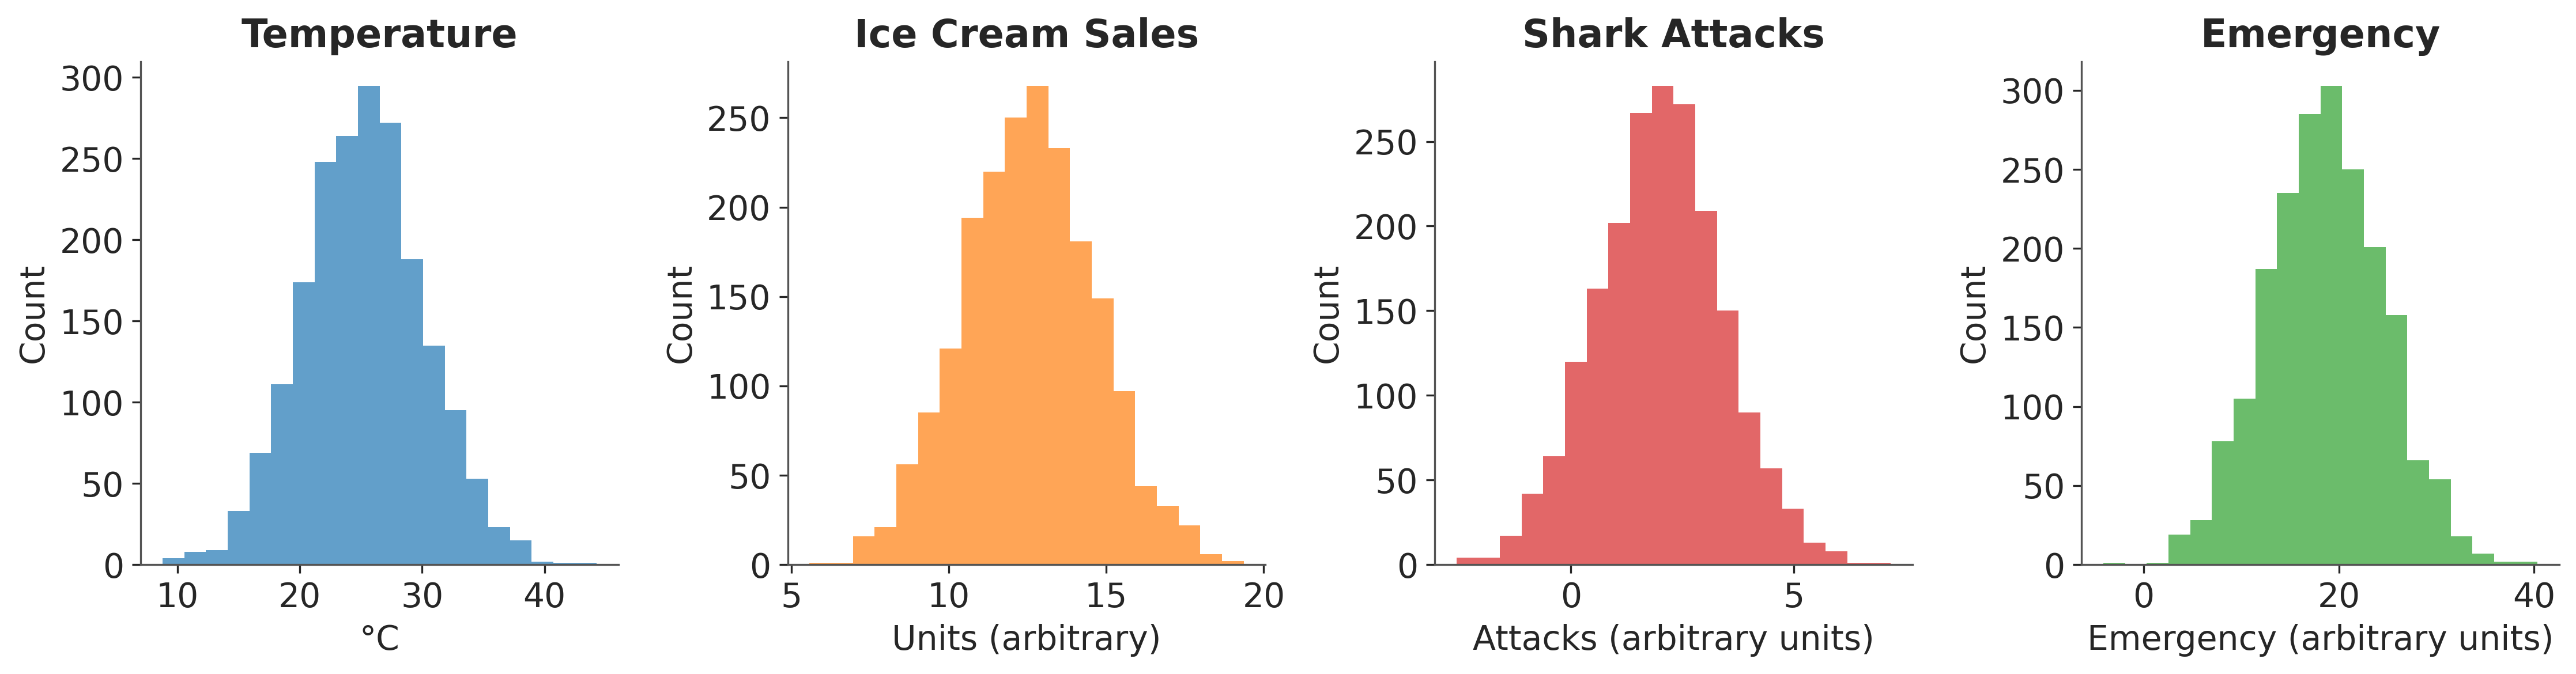

/var/folders/w2/9c3nwdfn5j9g0_gpy7gsbspc0000gn/T/ipykernel_28840/1345163549.py:43: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=4, loc="upper left", bbox_to_anchor=(1, 1))


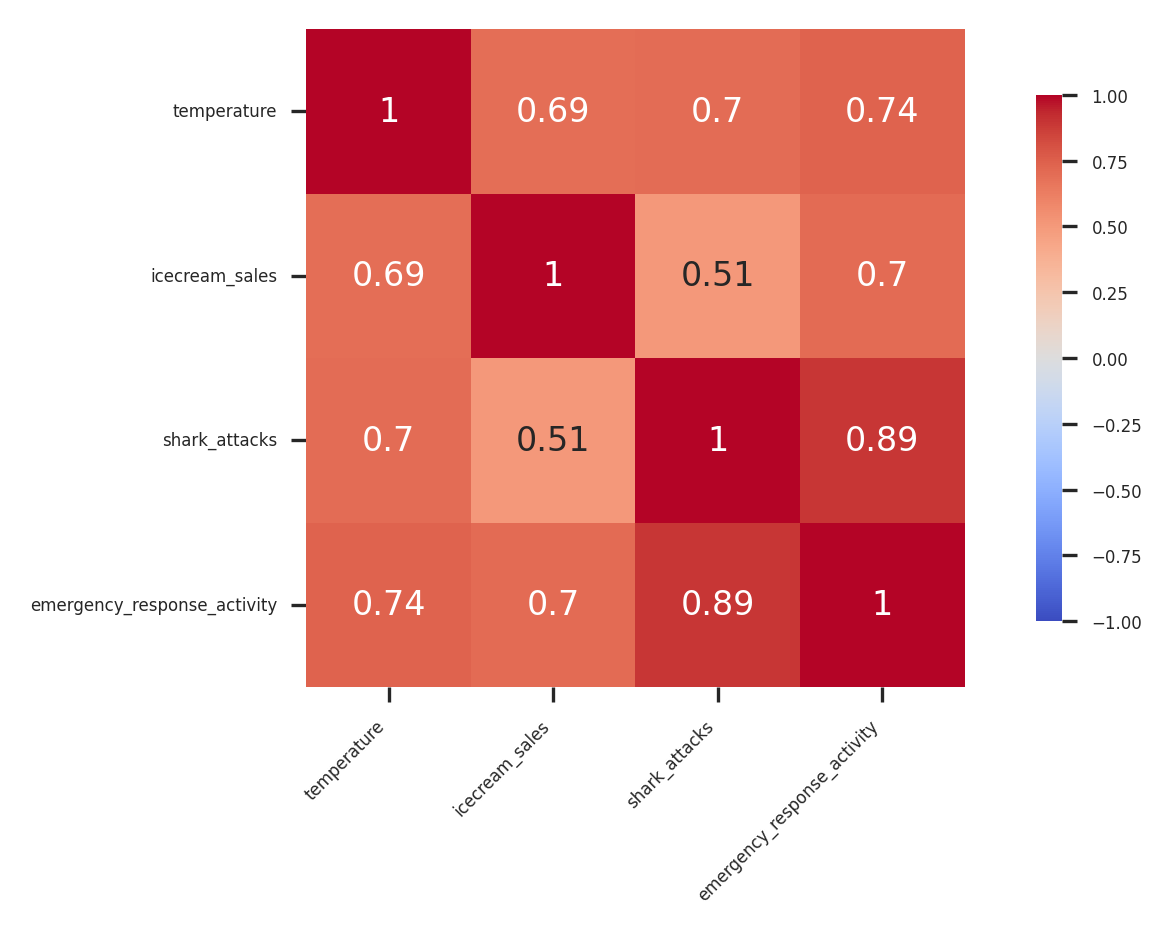

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

axes[0].hist(shark_data["temperature"], bins=20, color="tab:blue", alpha=0.7)
axes[0].set_title("Temperature")
axes[0].set_xlabel("°C")
axes[0].set_ylabel("Count")

axes[1].hist(shark_data["icecream_sales"], bins=20, color="tab:orange", alpha=0.7)
axes[1].set_title("Ice Cream Sales")
axes[1].set_xlabel("Units (arbitrary)")
axes[1].set_ylabel("Count")

axes[2].hist(shark_data["shark_attacks"], bins=20, color="tab:red", alpha=0.7)
axes[2].set_title("Shark Attacks")
axes[2].set_xlabel("Attacks (arbitrary units)")
axes[2].set_ylabel("Count")

axes[3].hist(shark_data["emergency_response_activity"], bins=20, color="tab:green", alpha=0.7)
axes[3].set_title("Emergency")
axes[3].set_xlabel("Emergency (arbitrary units)")
axes[3].set_ylabel("Count")

plt.tight_layout()
plt.show()

corr = shark_data[
    ["temperature", "icecream_sales", "shark_attacks", "emergency_response_activity"]
].corr()
plt.figure(figsize=(4, 3))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    annot_kws={"fontsize": 8},
    cbar_kws={"shrink": 0.8},
)
# plt.title("Correlation Matrix", fontsize=8)
plt.xticks(fontsize=4, rotation=45, ha="right")
plt.yticks(fontsize=4)
plt.legend(fontsize=4, loc="upper left", bbox_to_anchor=(1, 1))
plt.gca().collections[0].colorbar.ax.tick_params(labelsize=4)
# plt.gca().collections[0].colorbar.set_label('Correlation', fontsize=4)
plt.show()

## Model I: SharkAttacks ~ IceCream

In [5]:
%%capture
model = BayesianLinearRegression(center_data=False)

X = shark_data[["icecream_sales"]]
y = shark_data["shark_attacks"]

posterior_df, fit = model.fit(X, y)
posterior_df.head()

In [6]:
posterior_df.head()

,chain__,iter__,draw__,lp__,accept_stat__,stepsize__,treedepth__,n_leapfrog__,divergent__,energy__,intercept,icecream_sales,sigma
0,1.0,1.0,1.0,-1382.84,0.993473,0.107262,5.0,31.0,0.0,1383.57,-2.50521,0.356233,1.22044
1,1.0,2.0,2.0,-1381.33,0.999165,0.107262,4.0,27.0,0.0,1386.06,-2.19116,0.333650,1.21514
2,1.0,3.0,3.0,-1381.63,0.911335,0.107262,4.0,21.0,0.0,1383.34,-2.14877,0.330477,1.22263
3,1.0,4.0,4.0,-1381.57,0.989055,0.107262,4.0,15.0,0.0,1381.76,-2.13762,0.329384,1.21886
4,1.0,5.0,5.0,-1382.01,0.988341,0.107262,4.0,15.0,0.0,1382.14,-2.05673,0.322648,1.21518


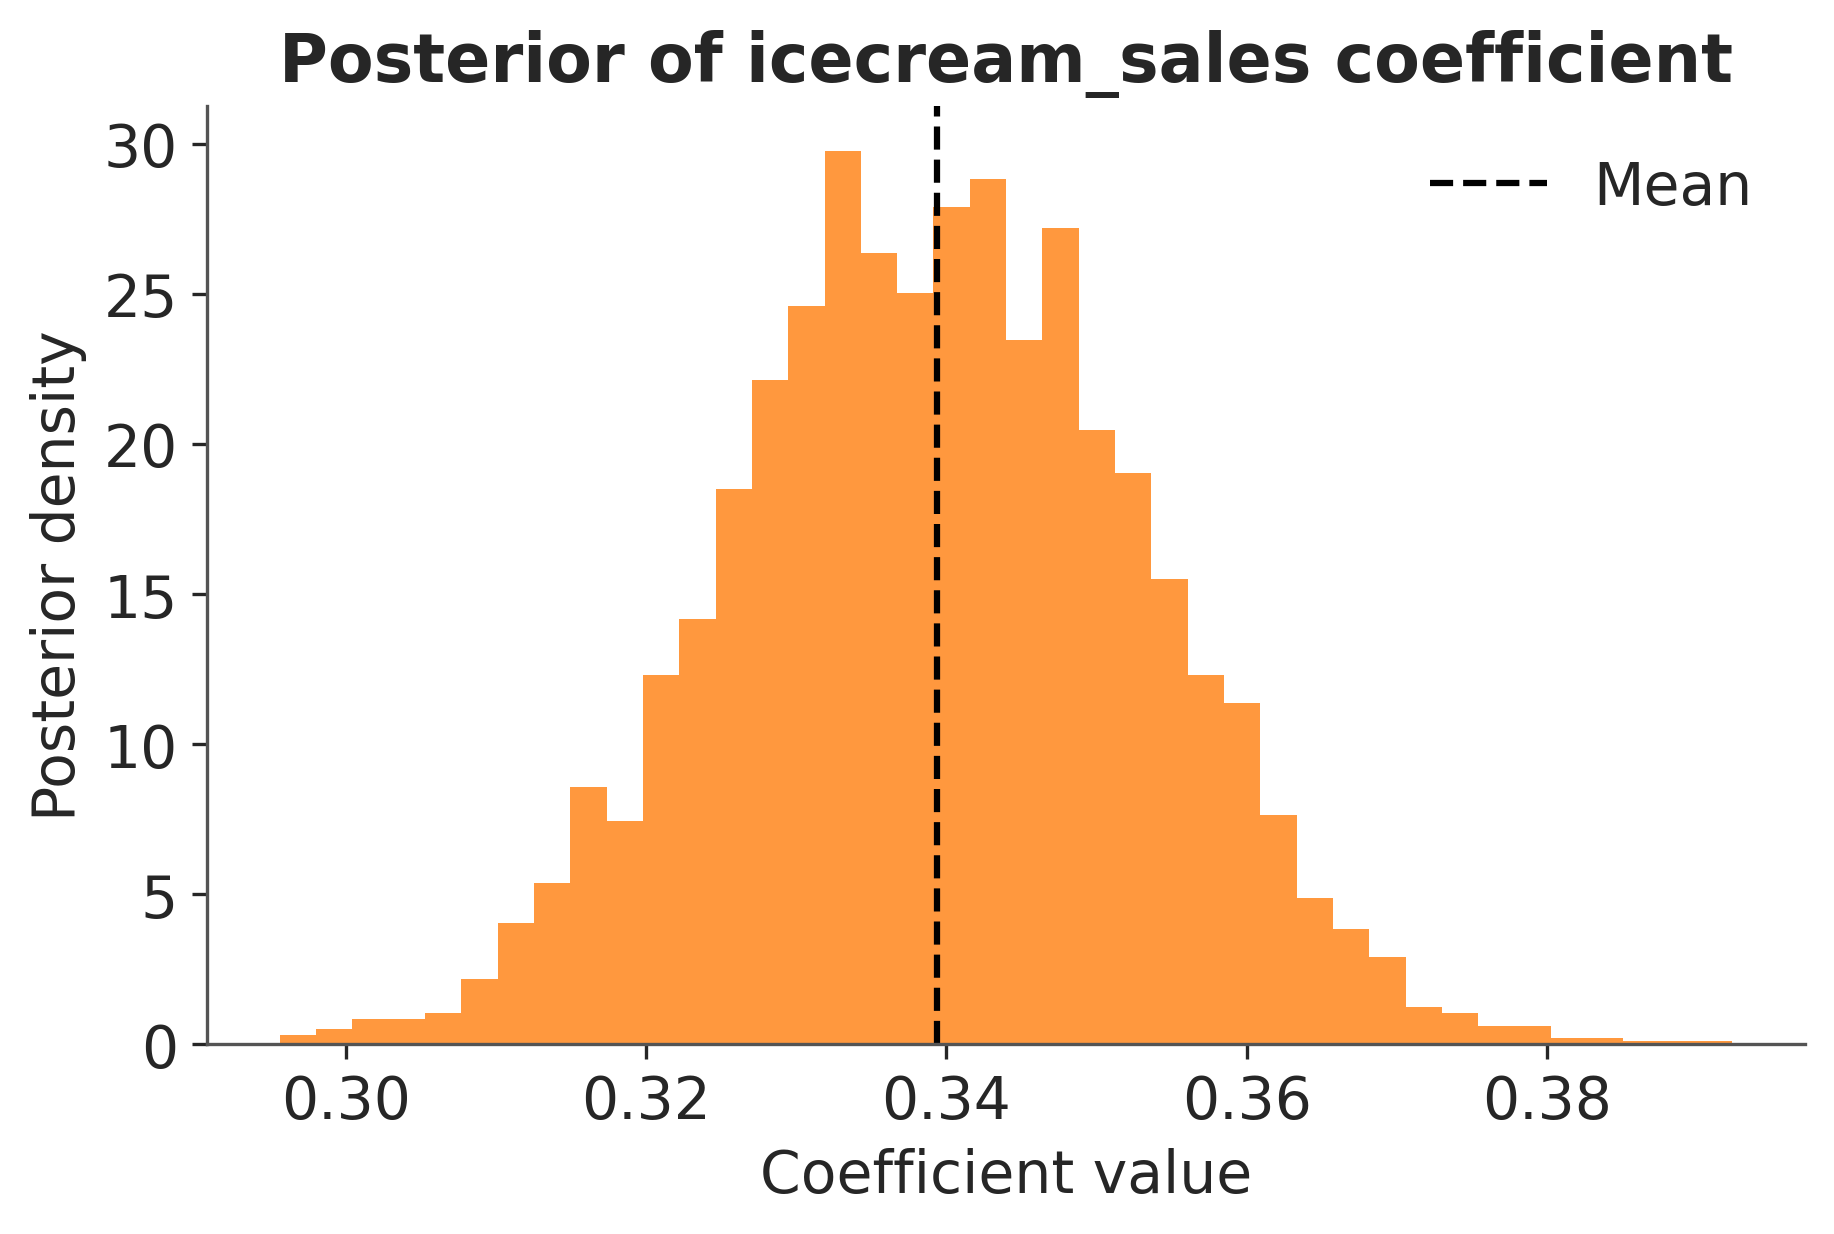

In [7]:
# Posterior histogram for the icecream_sales coefficient
coef_samples = posterior_df["icecream_sales"]

plt.figure(figsize=(6, 4))
plt.hist(coef_samples, bins=40, color="tab:orange", alpha=0.8, density=True)
plt.axvline(coef_samples.mean(), color="black", linestyle="--", label="Mean")
plt.title("Posterior of icecream_sales coefficient")
plt.xlabel("Coefficient value")
plt.ylabel("Posterior density")
plt.legend()
plt.show()

## Model II: SharkAttacks ~ IceCream + Temperature

In [8]:
%%capture
model = BayesianLinearRegression(center_data=False)

X = shark_data[["icecream_sales", "temperature"]]
y = shark_data["shark_attacks"]

posterior_df, fit = model.fit(X, y)
posterior_df.head()

/var/folders/w2/9c3nwdfn5j9g0_gpy7gsbspc0000gn/T/ipykernel_28840/2794771750.py:23: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


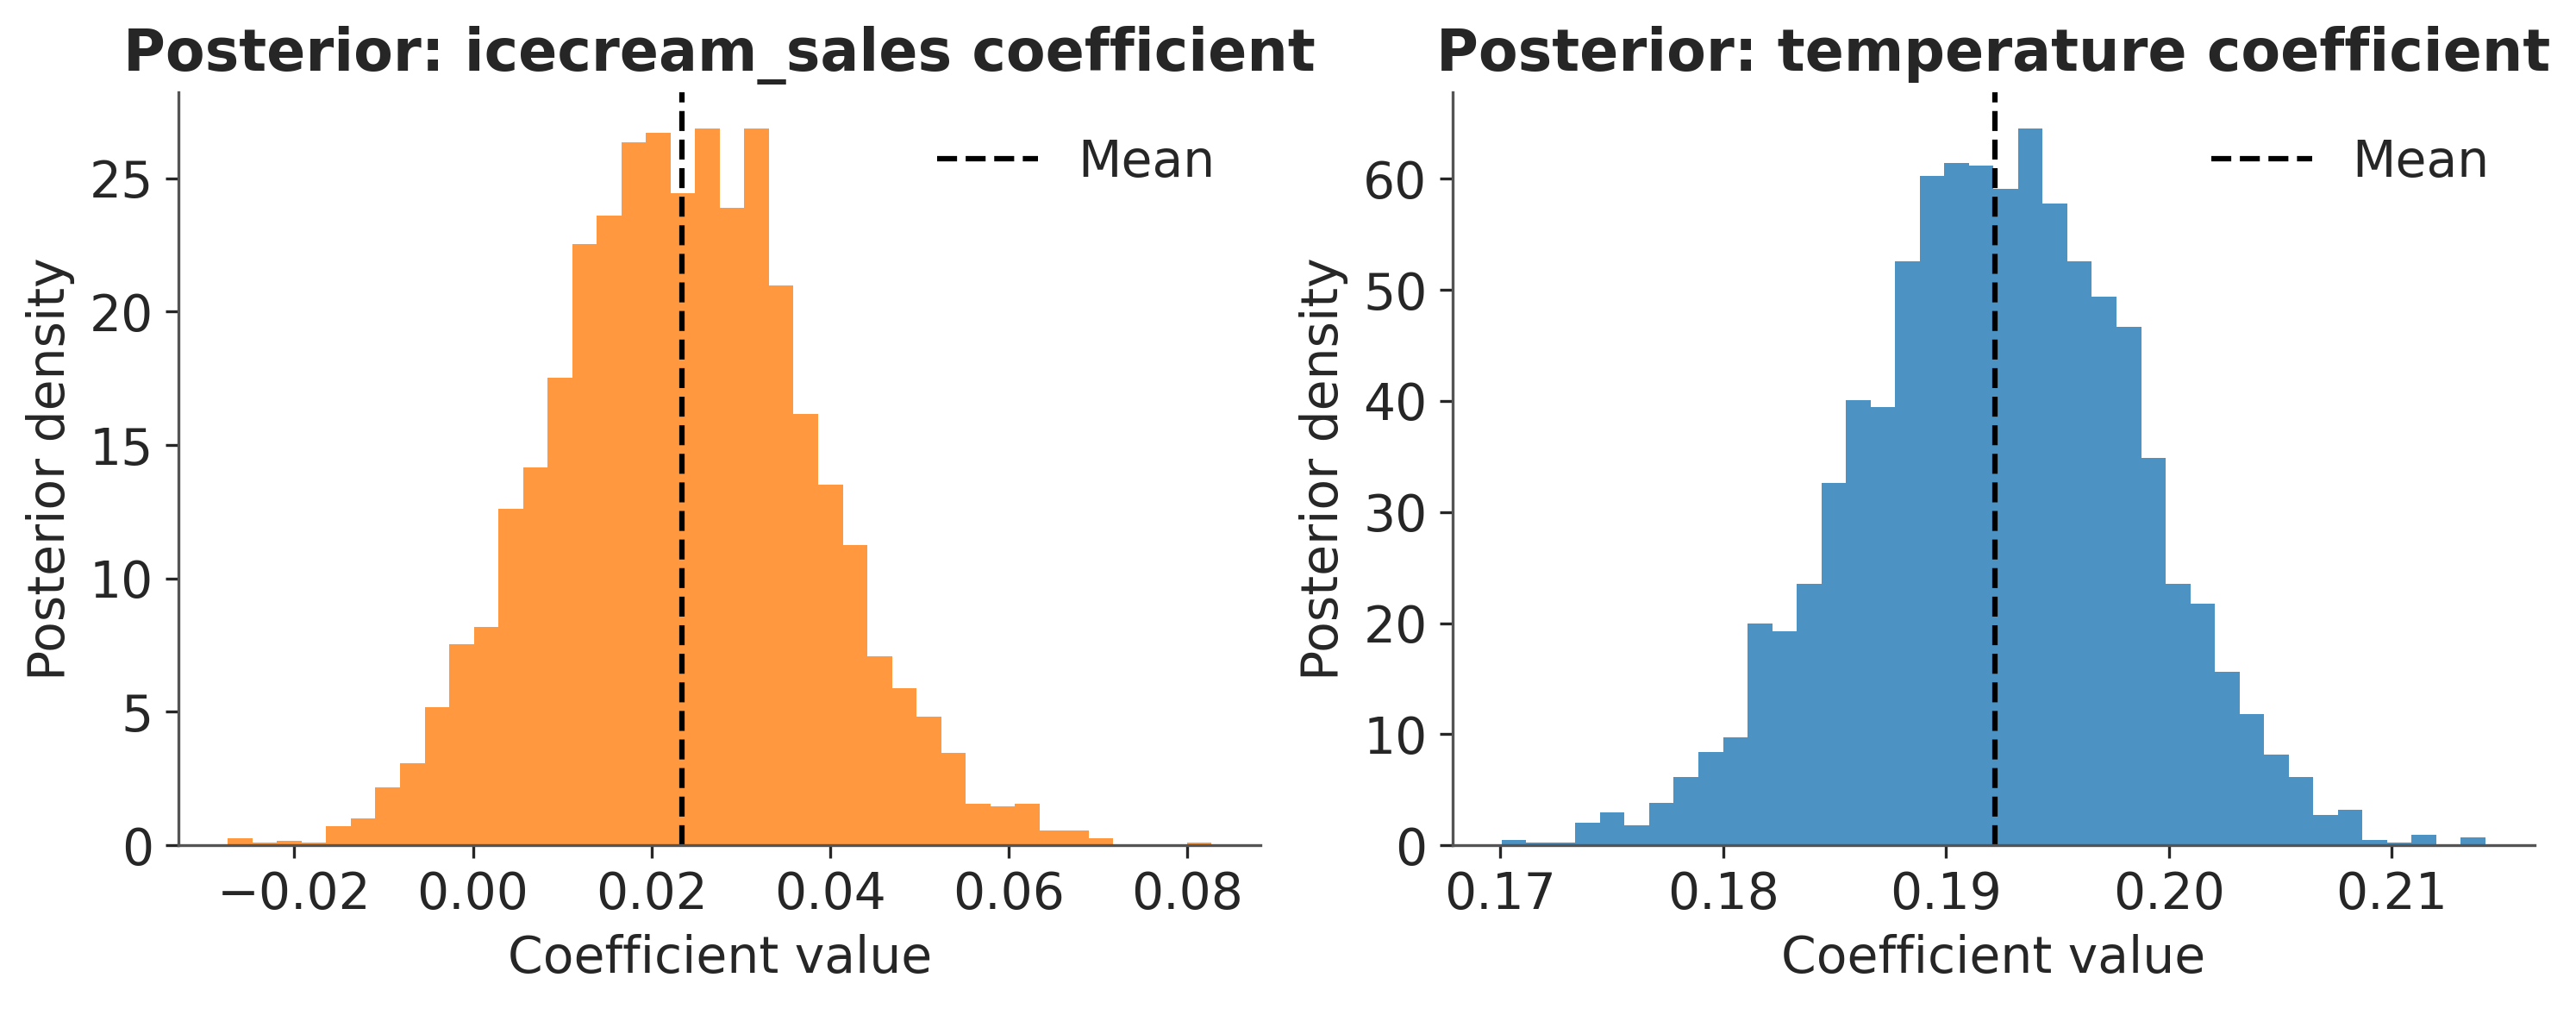

In [9]:
# Posterior histograms for the icecream_sales and temperature coefficients
coef_icecream = posterior_df["icecream_sales"]
coef_temp = posterior_df["temperature"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Ice cream sales coefficient
axes[0].hist(coef_icecream, bins=40, color="tab:orange", alpha=0.8, density=True)
axes[0].axvline(coef_icecream.mean(), color="black", linestyle="--", label="Mean")
axes[0].set_title("Posterior: icecream_sales coefficient")
axes[0].set_xlabel("Coefficient value")
axes[0].set_ylabel("Posterior density")
axes[0].legend()

# Temperature coefficient
axes[1].hist(coef_temp, bins=40, color="tab:blue", alpha=0.8, density=True)
axes[1].axvline(coef_temp.mean(), color="black", linestyle="--", label="Mean")
axes[1].set_title("Posterior: temperature coefficient")
axes[1].set_xlabel("Coefficient value")
axes[1].set_ylabel("Posterior density")
axes[1].legend()

plt.tight_layout()
plt.show()

In [10]:
# Classical (frequentist) multiple regression: shark_attacks ~ icecream_sales + temperature
from sklearn.linear_model import LinearRegression

X_classical = shark_data[["icecream_sales", "temperature"]]
y_classical = shark_data["shark_attacks"]

linreg = LinearRegression(fit_intercept=True)
linreg.fit(X_classical, y_classical)

intercept = linreg.intercept_
coefs = linreg.coef_
r2 = linreg.score(X_classical, y_classical)

results_df = pd.DataFrame(
    {
        "term": ["intercept", "icecream_sales", "temperature"],
        "estimate": [intercept, coefs[0], coefs[1]],
    }
)

print("Frequentist multiple regression (OLS) results:\n")
print(results_df)
print(f"\nR-squared: {r2:.3f}")

Frequentist multiple regression (OLS) results:

             term  estimate
0       intercept -3.149024
1  icecream_sales  0.023709
2     temperature  0.192201

R-squared: 0.493


## Model III: SharkAttacks ~ IceCream + Temperature + EmergencyResponse

In [11]:
%%capture
model = BayesianLinearRegression(center_data=False)

X = shark_data[["icecream_sales", "temperature", "emergency_response_activity"]]
y = shark_data["shark_attacks"]

posterior_df, fit = model.fit(X, y)
posterior_df.head()

/var/folders/w2/9c3nwdfn5j9g0_gpy7gsbspc0000gn/T/ipykernel_28840/3077897216.py:32: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


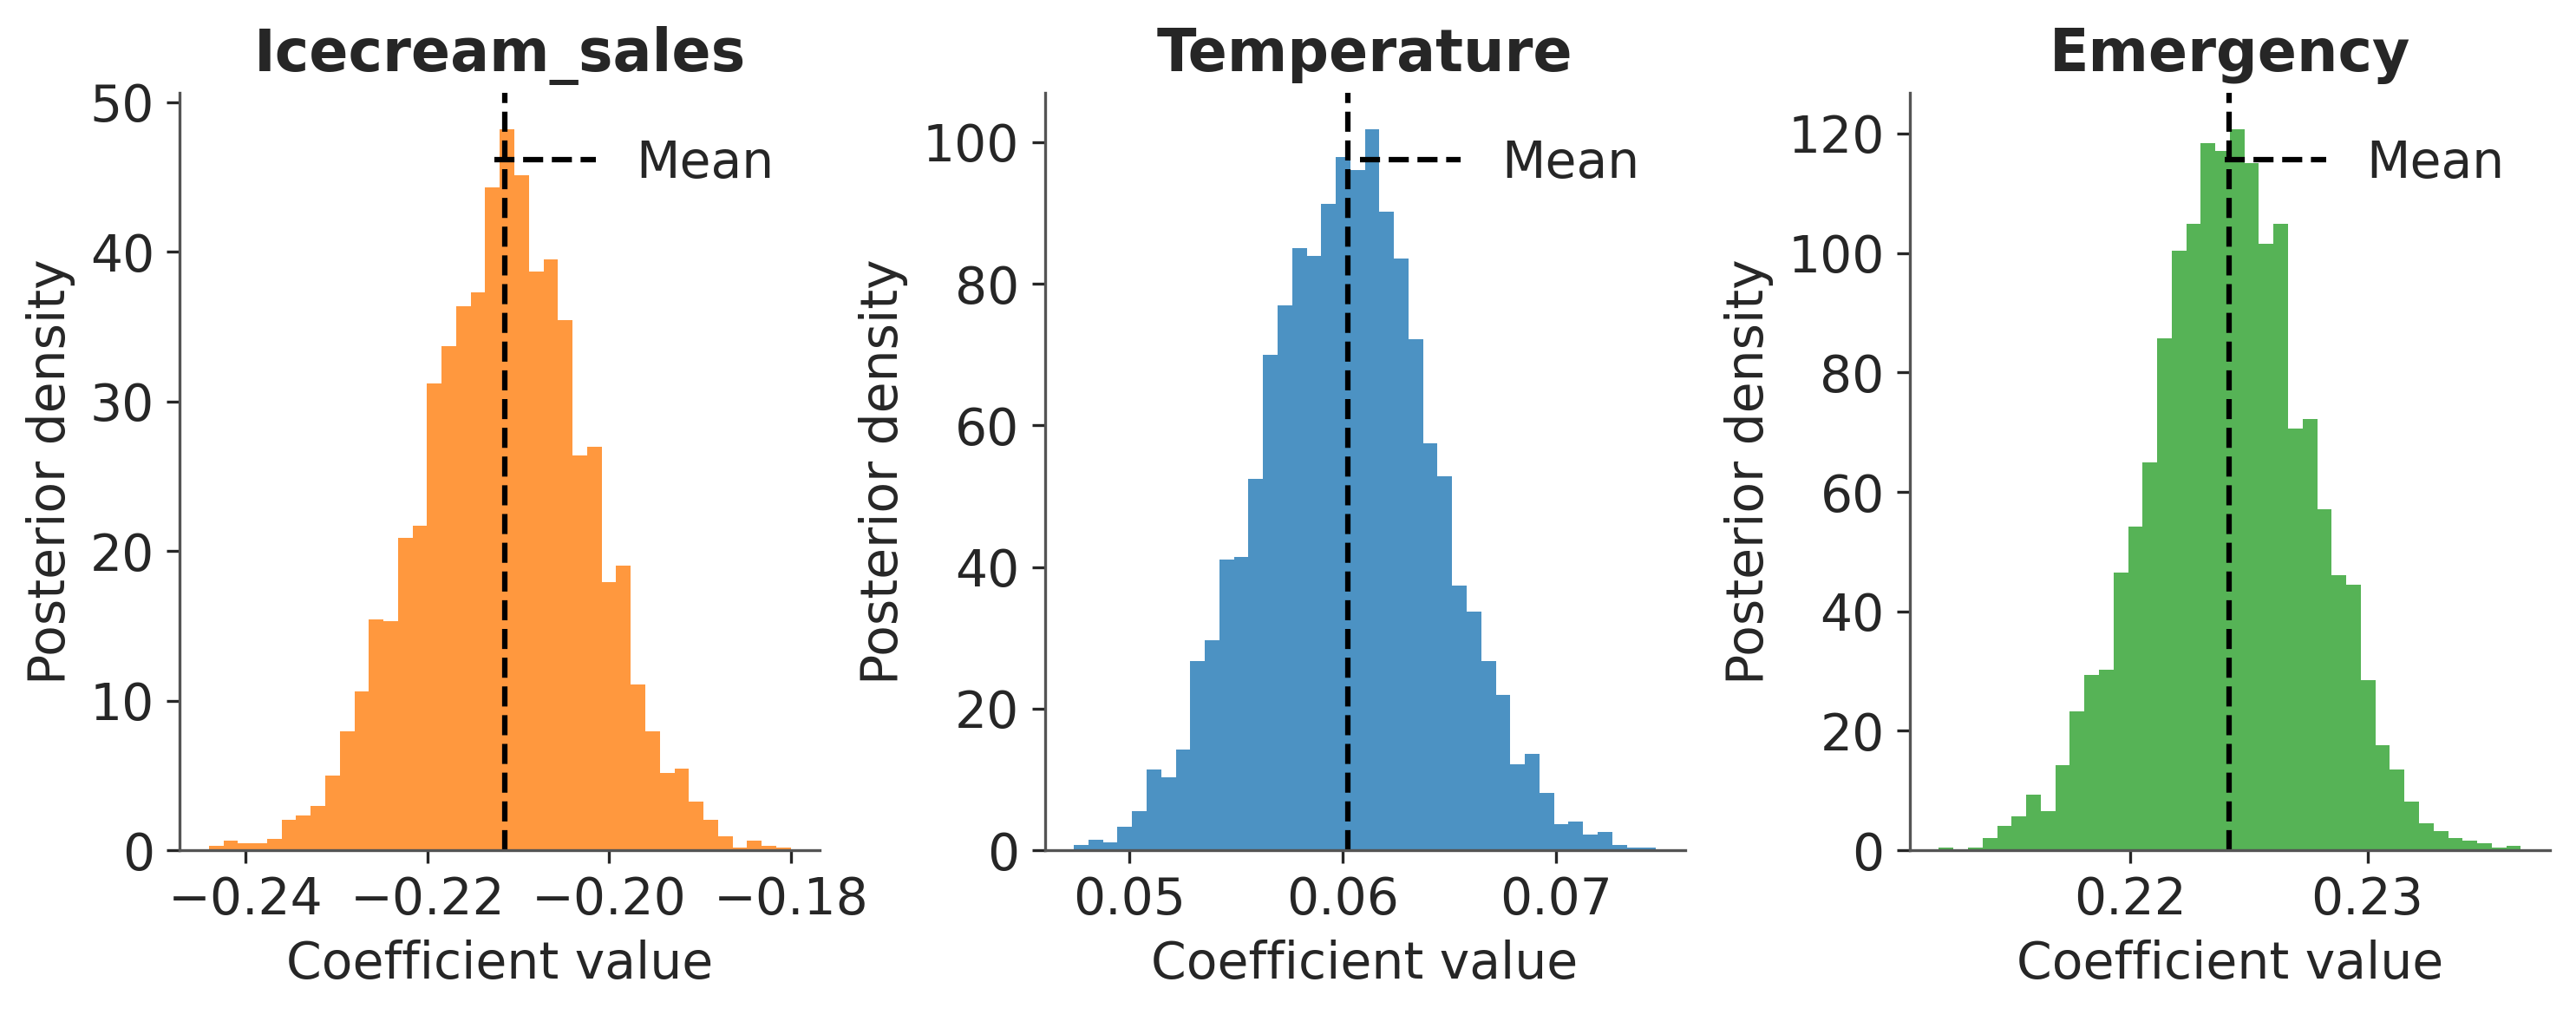

In [12]:
# Posterior histograms for the icecream_sales and temperature coefficients
coef_icecream = posterior_df["icecream_sales"]
coef_temp = posterior_df["temperature"]
coef_emergency = posterior_df["emergency_response_activity"]

fig, axes = plt.subplots(1, 3, figsize=(10, 4))

# Ice cream sales coefficient
axes[0].hist(coef_icecream, bins=40, color="tab:orange", alpha=0.8, density=True)
axes[0].axvline(coef_icecream.mean(), color="black", linestyle="--", label="Mean")
axes[0].set_title("Icecream_sales")
axes[0].set_xlabel("Coefficient value")
axes[0].set_ylabel("Posterior density")
axes[0].legend()

# Temperature coefficient
axes[1].hist(coef_temp, bins=40, color="tab:blue", alpha=0.8, density=True)
axes[1].axvline(coef_temp.mean(), color="black", linestyle="--", label="Mean")
axes[1].set_title("Temperature")
axes[1].set_xlabel("Coefficient value")
axes[1].set_ylabel("Posterior density")
axes[1].legend()

# Emergency coefficient
axes[2].hist(coef_emergency, bins=40, color="tab:green", alpha=0.8, density=True)
axes[2].axvline(coef_emergency.mean(), color="black", linestyle="--", label="Mean")
axes[2].set_title("Emergency")
axes[2].set_xlabel("Coefficient value")
axes[2].set_ylabel("Posterior density")
axes[2].legend()

plt.tight_layout()
plt.show()